# Review 2 — Agglomerative Hierarchical Clustering

**Algorithm 2: Agglomerative Hierarchical Clustering**  
**Dataset:** Iris dataset (same dataset structure as `classification.ipynb`)  

### Objectives
- Prepare and scale the Iris features.
- Plot a dendrogram to inspect possible cluster groupings.
- Compare `ward`, `complete`, `average`, and `single` linkage strategies.
- Evaluate cluster separation with the silhouette score.
- Visualize the resulting clusters and compare them with known species labels only for interpretation.

> Clustering is unsupervised. The `species` column is not used to create clusters; it is used only at the end for an optional external comparison.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the dataset

In [2]:
# Use the same Iris dataset and column names as the reference classification notebook.
# This cell loads the local CSV when available; otherwise it recreates the same dataset
# from scikit-learn's built-in Iris data so the notebook is self-contained.
try:
    df = pd.read_csv("IRIS.csv")
except FileNotFoundError:
    iris = load_iris(as_frame=True)
    df = iris.frame.copy()
    df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species_code"]
    df["species"] = df["species_code"].map({i: f"Iris-{name}" for i, name in enumerate(iris.target_names)})
    df = df.drop(columns=["species_code"])

print("First five rows:")
display(df.head())
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe())

First five rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Dataset shape: (150, 5)

Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Summary statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Prepare the features

In [3]:
# Species is excluded from clustering because it is a known label.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols].copy()
y_species = df["species"].copy() if "species" in df.columns else None

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature matrix shape:", X.shape)
print("Scaled matrix shape:", X_scaled.shape)
print("\nScaled feature means (approximately 0):", np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature standard deviations (approximately 1):", np.round(X_scaled.std(axis=0), 3))

Feature matrix shape: (150, 4)
Scaled matrix shape: (150, 4)

Scaled feature means (approximately 0): [-0. -0. -0. -0.]
Scaled feature standard deviations (approximately 1): [1. 1. 1. 1.]


## 4. Explore feature relationships

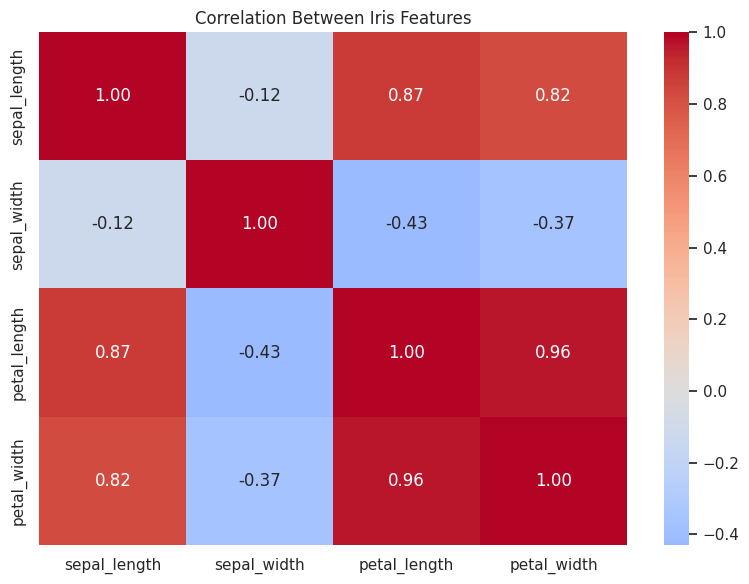

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

## 5. Dendrogram — Ward linkage

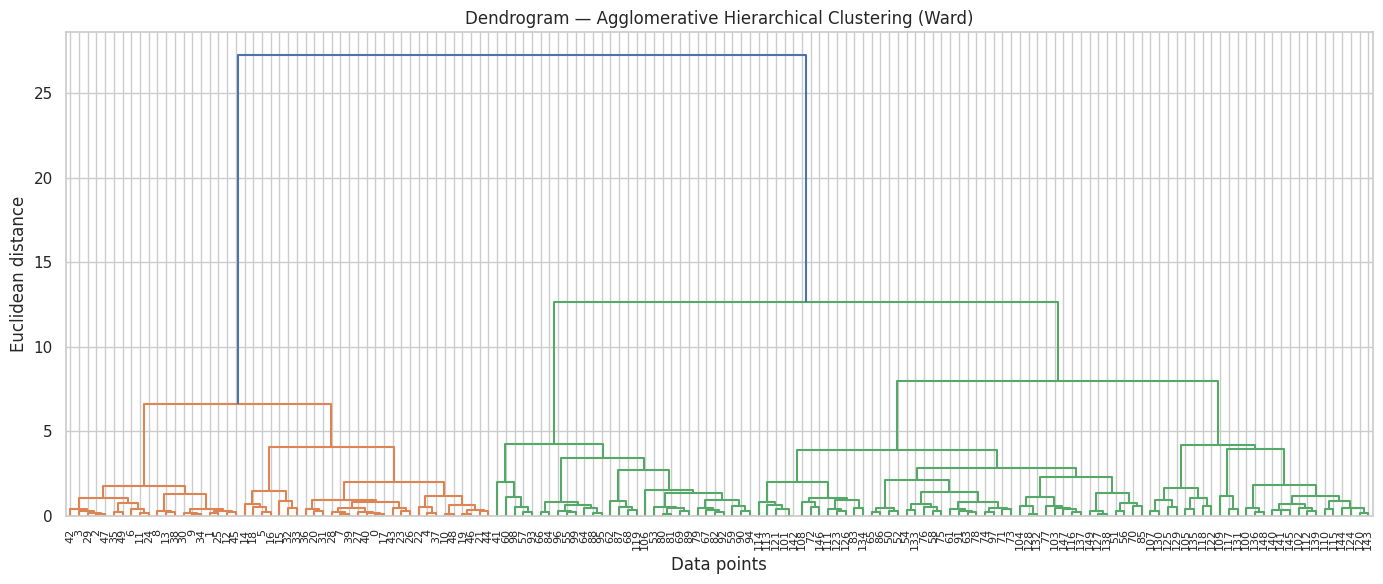

Interpretation: look for large vertical gaps between merges; a horizontal cut across such a gap suggests a possible cluster count.


In [5]:
# Ward linkage minimizes the increase in within-cluster variance at each merge.
Z_ward = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z_ward, labels=None, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram — Agglomerative Hierarchical Clustering (Ward)")
plt.xlabel("Data points")
plt.ylabel("Euclidean distance")
plt.tight_layout()
plt.show()

print("Interpretation: look for large vertical gaps between merges; a horizontal cut across such a gap suggests a possible cluster count.")

## 6. Compare linkage strategies using silhouette score

In [6]:
linkage_methods = ["ward", "complete", "average", "single"]
comparison_rows = []
labels_by_linkage = {}

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_scaled)
    labels_by_linkage[method] = labels
    score = silhouette_score(X_scaled, labels)
    comparison_rows.append({
        "Linkage": method,
        "Number of clusters": len(np.unique(labels)),
        "Silhouette score": score
    })

results_df = pd.DataFrame(comparison_rows).sort_values("Silhouette score", ascending=False).reset_index(drop=True)
display(results_df.style.format({"Silhouette score": "{:.4f}"}))

best_linkage = results_df.loc[0, "Linkage"]
print(f"Best linkage by silhouette score for this run: {best_linkage}")

,Linkage,Number of clusters,Silhouette score
0,single,3,0.5046
1,average,3,0.4803
2,complete,3,0.4496
3,ward,3,0.4467


Best linkage by silhouette score for this run: single


## 7. Plot silhouette score comparison

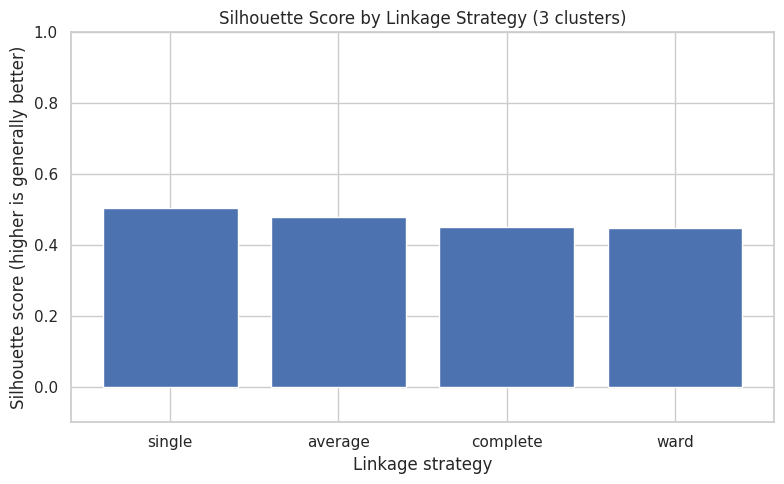

In [7]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Linkage"], results_df["Silhouette score"])
plt.title("Silhouette Score by Linkage Strategy (3 clusters)")
plt.xlabel("Linkage strategy")
plt.ylabel("Silhouette score (higher is generally better)")
plt.ylim(-0.1, 1.0)
plt.tight_layout()
plt.show()

## 8. Visualize the best linkage result

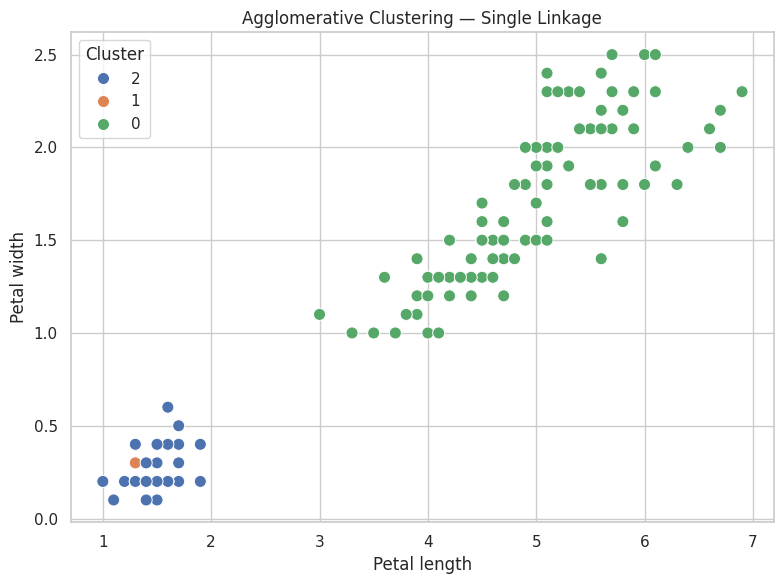

In [8]:
best_labels = labels_by_linkage[best_linkage]
plot_df = X.copy()
plot_df["Cluster"] = best_labels.astype(str)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="petal_length", y="petal_width", hue="Cluster", palette="deep", s=75)
plt.title(f"Agglomerative Clustering — {best_linkage.title()} Linkage")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 9. Inspect cluster sizes and feature averages

In [9]:
cluster_summary = X.copy()
cluster_summary["Cluster"] = best_labels
print("Number of points in each cluster:")
display(cluster_summary["Cluster"].value_counts().sort_index().rename_axis("Cluster").to_frame("Count"))
print("\nMean feature values per cluster:")
display(cluster_summary.groupby("Cluster")[feature_cols].mean().round(2))

Number of points in each cluster:


,Count
Cluster,
0,100
1,1
2,49



Mean feature values per cluster:


,sepal_length,sepal_width,petal_length,petal_width
Cluster,,,,
0,6.26,2.87,4.91,1.68
1,4.50,2.30,1.30,0.30
2,5.02,3.45,1.47,0.24


## 10. Optional comparison with species labels

In [10]:
# Species labels are NOT used to fit the clustering model. Adjusted Rand Index (ARI)
# is shown only as an external comparison because this dataset has known species labels.
if y_species is not None:
    ari = adjusted_rand_score(y_species, best_labels)
    print(f"Adjusted Rand Index (ARI) against species labels: {ari:.4f}")
    print("ARI is 1.0 for a perfect match up to label permutation; values near 0 indicate chance-level agreement.")
else:
    print("No species labels available; skipping ARI.")

Adjusted Rand Index (ARI) against species labels: 0.5584
ARI is 1.0 for a perfect match up to label permutation; values near 0 indicate chance-level agreement.
